Shape: (891, 12)

First 5 rows:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373

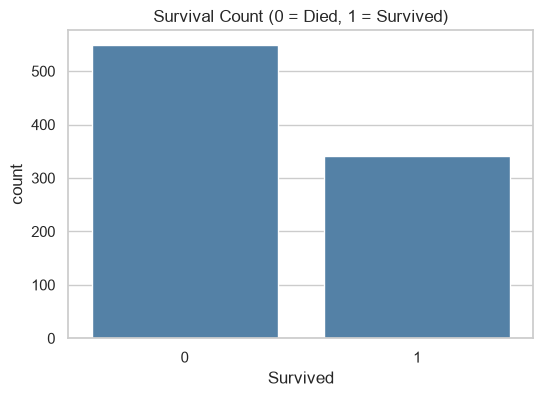

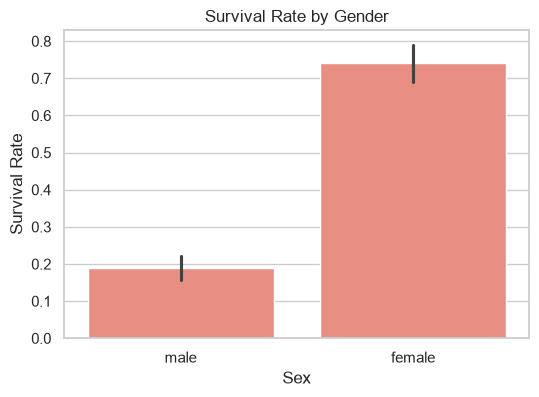

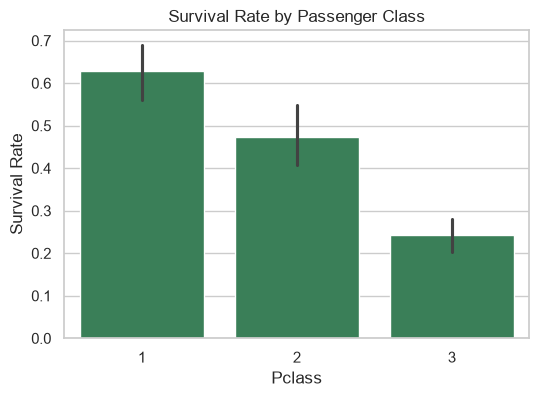

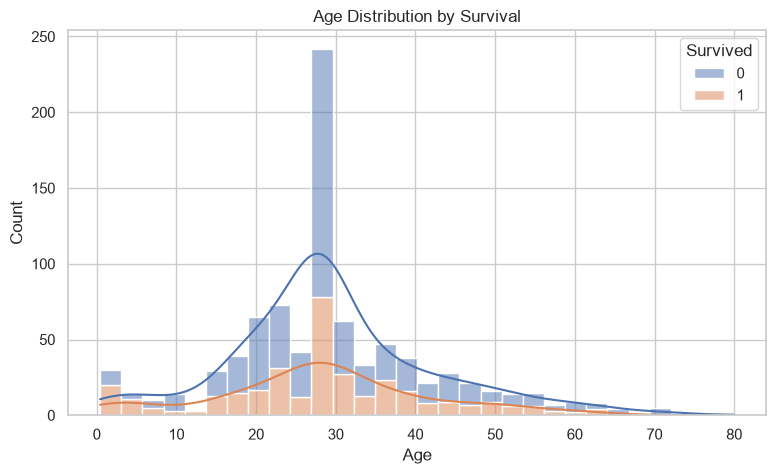

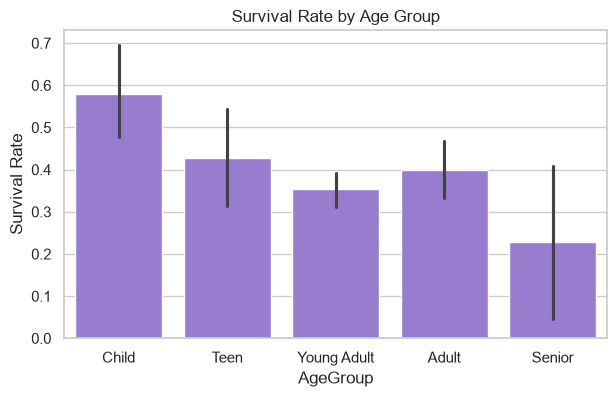

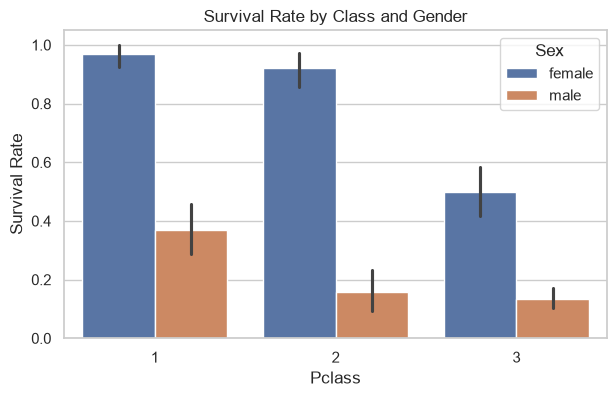

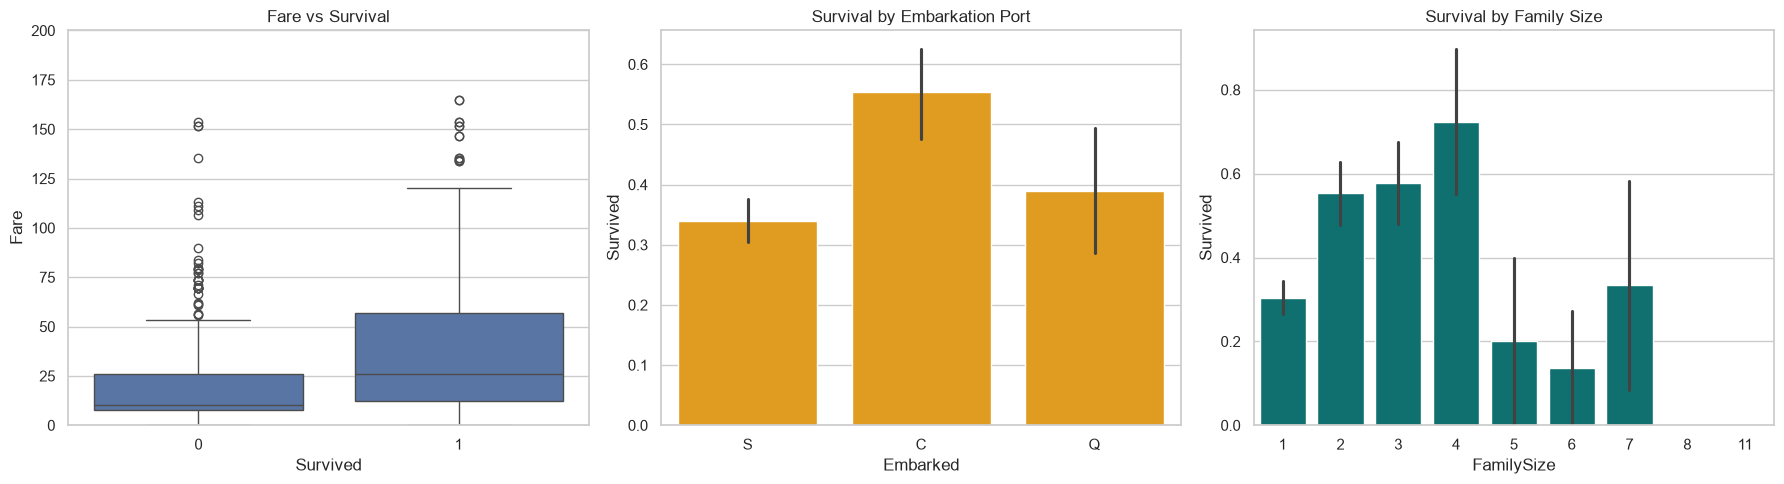

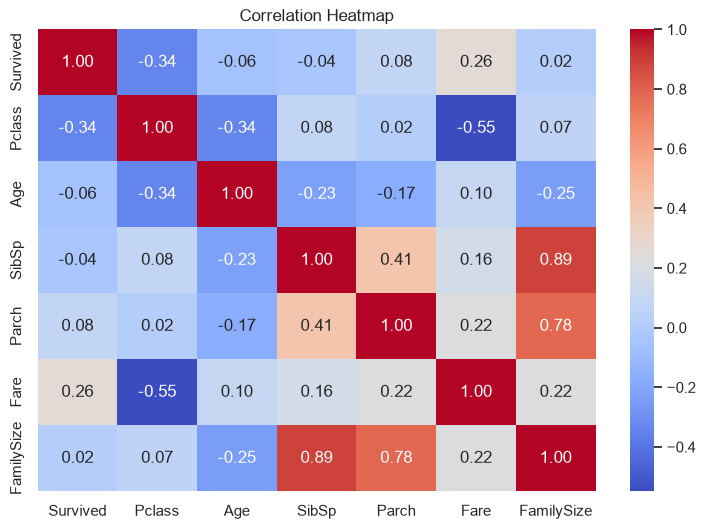


Analysis complete! Charts 'images/' folder mein save ho gaye.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
os.makedirs("images", exist_ok=True)

# ---------- 1. Data load ----------
df = pd.read_csv("train.csv")
print("Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())
print("\nInfo:")
df.info()
print("\nStatistics:")
print(df.describe())
print("\nMissing values (before cleaning):")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

# ---------- 2. Data cleaning ----------
# Assumption 1: Age ke missing values median se fill
df["Age"] = df["Age"].fillna(df["Age"].median())
# Assumption 2: Embarked ke missing values mode se fill
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
# Assumption 3: Cabin mein bahut zyada data missing hai, isliye drop
df = df.drop(columns=["Cabin"])
df = df.drop_duplicates()

# New features
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teen", "Young Adult", "Adult", "Senior"],
)

print("\nMissing values (after cleaning):")
print(df.isnull().sum())

# ---------- 3. Survival statistics ----------
print(f"\nOverall survival rate: {df['Survived'].mean() * 100:.2f}%")
print("\nSurvival % by Gender:\n", (df.groupby("Sex")["Survived"].mean() * 100).round(2))
print("\nSurvival % by Class:\n", (df.groupby("Pclass")["Survived"].mean() * 100).round(2))
print("\nSurvival % by Age Group:\n", (df.groupby("AgeGroup", observed=True)["Survived"].mean() * 100).round(2))

# ---------- 4. Visualizations ----------
# Chart 1: Overall survival count
plt.figure(figsize=(6, 4))
sns.countplot(x="Survived", data=df, color="steelblue")
plt.title("Survival Count (0 = Died, 1 = Survived)")
plt.savefig("images/survival_count.png", bbox_inches="tight")
plt.show()

# Chart 2: Gender
plt.figure(figsize=(6, 4))
sns.barplot(x="Sex", y="Survived", data=df, color="salmon")
plt.title("Survival Rate by Gender")
plt.ylabel("Survival Rate")
plt.savefig("images/survival_gender.png", bbox_inches="tight")
plt.show()

# Chart 3: Passenger class
plt.figure(figsize=(6, 4))
sns.barplot(x="Pclass", y="Survived", data=df, color="seagreen")
plt.title("Survival Rate by Passenger Class")
plt.ylabel("Survival Rate")
plt.savefig("images/survival_class.png", bbox_inches="tight")
plt.show()

# Chart 4: Age distribution + age group
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="Age", hue="Survived", bins=30, kde=True, multiple="stack")
plt.title("Age Distribution by Survival")
plt.savefig("images/age_distribution.png", bbox_inches="tight")
plt.show()

plt.figure(figsize=(7, 4))
sns.barplot(x="AgeGroup", y="Survived", data=df, color="mediumpurple")
plt.title("Survival Rate by Age Group")
plt.ylabel("Survival Rate")
plt.savefig("images/survival_agegroup.png", bbox_inches="tight")
plt.show()

# Chart 5: Class + Gender
plt.figure(figsize=(7, 4))
sns.barplot(x="Pclass", y="Survived", hue="Sex", data=df)
plt.title("Survival Rate by Class and Gender")
plt.ylabel("Survival Rate")
plt.savefig("images/class_gender.png", bbox_inches="tight")
plt.show()

# Chart 6: Fare, Embarked, Family size
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(x="Survived", y="Fare", data=df, ax=axes[0])
axes[0].set_title("Fare vs Survival")
axes[0].set_ylim(0, 200)
sns.barplot(x="Embarked", y="Survived", data=df, ax=axes[1], color="orange")
axes[1].set_title("Survival by Embarkation Port")
sns.barplot(x="FamilySize", y="Survived", data=df, ax=axes[2], color="teal")
axes[2].set_title("Survival by Family Size")
plt.tight_layout()
plt.savefig("images/fare_port_family.png", bbox_inches="tight")
plt.show()

# Chart 7: Correlation heatmap
num_df = df[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare", "FamilySize"]]
plt.figure(figsize=(9, 6))
sns.heatmap(num_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.savefig("images/correlation_heatmap.png", bbox_inches="tight")
plt.show()

print("\nAnalysis complete! Charts 'images/' folder mein save ho gaye.")